# Per-epitope specificity predictions

Breakdown performance of AlphaFold 3 at predicting T cell antigen specificity by each significant epitope in the dataset.

In [1]:
import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')

In [3]:
sequences['epitope_id'] = sequences[['peptide', 'mhc1', 'mhc2']].apply('_'.join, axis=1)
num_epitopes = len(sequences['epitope_id'].unique())

print('Total number of epitopes:', num_epitopes)

Total number of epitopes: 207


In [4]:
epitope_label_counts = (
    sequences.value_counts(['epitope_id', 'label'])
    .reset_index()
    .pivot_table(index='epitope_id', columns='label', values='count')
    .fillna(0)
    .astype(int)
)
valid_epitope_ids = epitope_label_counts[(epitope_label_counts[0] > 0) & (epitope_label_counts[1] > 0)].index

print('Number of epitopes removed:', num_epitopes - len(valid_epitope_ids))

sequences_valid = sequences[sequences['epitope_id'].isin(valid_epitope_ids)]

Number of epitopes removed: 129


In [5]:
confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
confidence_scores = confidence_scores.merge(sequences_valid, how='inner', left_on='name', right_index=True)

In [6]:
per_epitope_roc_aucs = (
    confidence_scores.groupby('epitope_id')
    .apply(
        lambda group: (1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score']), len(group['name'].unique())),
        include_groups=False,
    )
    .apply(pd.Series)
)
per_epitope_roc_aucs.columns = ['roc_auc_score', 'number_of_complexes']

per_epitope_roc_aucs['number_of_complexes'] = per_epitope_roc_aucs['number_of_complexes'].astype(int)

per_epitope_roc_aucs = per_epitope_roc_aucs.sort_values('number_of_complexes', ascending=False)

In [7]:
with pd.option_context('display.max_rows', len(per_epitope_roc_aucs)):
    ipy_display.display(per_epitope_roc_aucs)

,roc_auc_score,number_of_complexes
epitope_id,,
RVRAYTYSK_HLA-A*03:01_B2M,0.483119,235
KSKRTPMGF_HLA-B*57:01_B2M,0.598753,169
VMATRRNVL_HLA-E*01:03_B2M,0.325475,166
RAKFKQLL_HLA-B*08:01_B2M,0.849586,113
VMTTVLATL_HLA-E*01:03_B2M,0.450237,78
RAQAPPPSW_HLA-B*57:01_B2M,0.492162,69
GILGFVFTL_HLA-A*02:01_B2M,0.758925,55
FLRGRAYGL_HLA-B*08:01_B2M,0.622206,33
KTFPPTEPK_HLA-A*03:01_B2M,0.516719,32


In [8]:
per_epitope_roc_aucs['roc_auc_score'].describe()

count    78.000000
mean      0.724962
std       0.302995
min       0.000000
25%       0.500000
50%       0.824793
75%       1.000000
max       1.000000
Name: roc_auc_score, dtype: float64

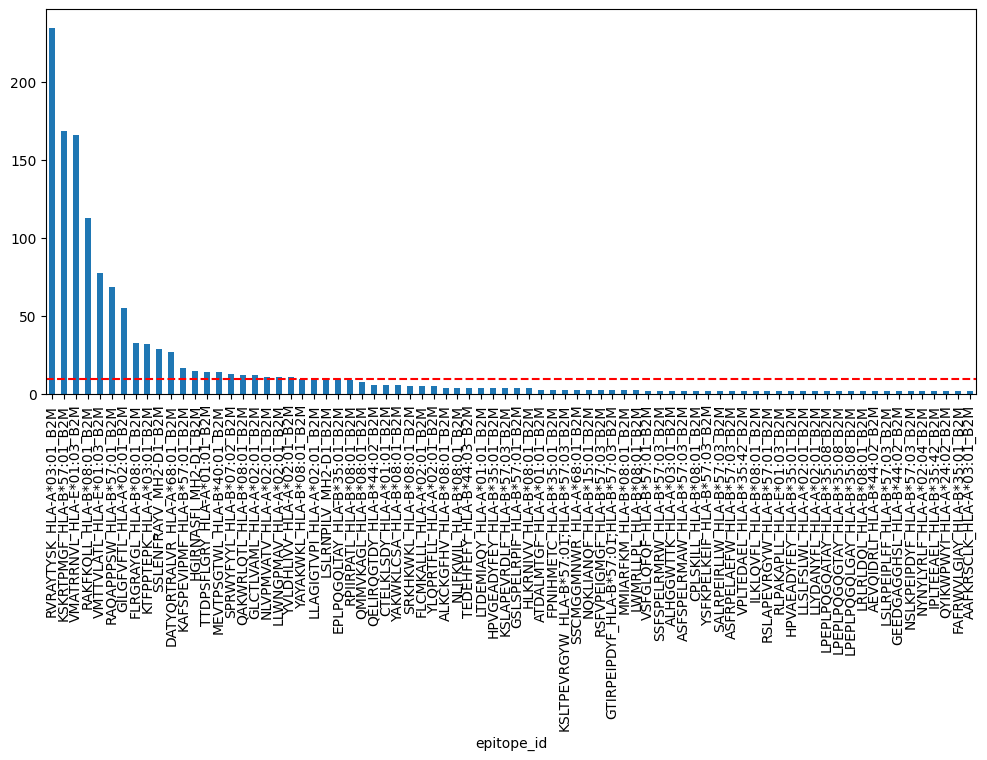

In [9]:
COUNT_CUTOFF = 10

ax = per_epitope_roc_aucs['number_of_complexes'].plot.bar(figsize=(12, 5))
ax.axhline(COUNT_CUTOFF, color='red', linestyle='dashed')

plt.show()

In [10]:
per_epitope_roc_aucs_filtered = per_epitope_roc_aucs[per_epitope_roc_aucs['number_of_complexes'] >= COUNT_CUTOFF]
print('Number of epitopes considered:', len(per_epitope_roc_aucs_filtered))

per_epitope_roc_aucs_filtered

Number of epitopes considered: 25


,roc_auc_score,number_of_complexes
epitope_id,,
RVRAYTYSK_HLA-A*03:01_B2M,0.483119,235
KSKRTPMGF_HLA-B*57:01_B2M,0.598753,169
VMATRRNVL_HLA-E*01:03_B2M,0.325475,166
RAKFKQLL_HLA-B*08:01_B2M,0.849586,113
VMTTVLATL_HLA-E*01:03_B2M,0.450237,78
RAQAPPPSW_HLA-B*57:01_B2M,0.492162,69
GILGFVFTL_HLA-A*02:01_B2M,0.758925,55
FLRGRAYGL_HLA-B*08:01_B2M,0.622206,33
KTFPPTEPK_HLA-A*03:01_B2M,0.516719,32


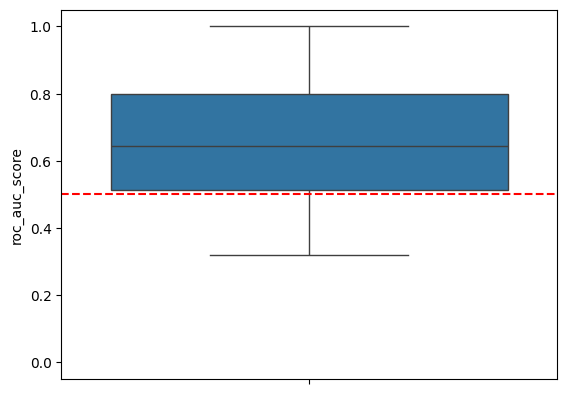

In [11]:
ax = sns.boxplot(per_epitope_roc_aucs_filtered, y='roc_auc_score')

ax.set_ylim(-0.05, 1.05)
ax.axhline(0.5, color='red', linestyle='dashed')
plt.show()

In [12]:
per_epitope_roc_aucs_filtered['roc_auc_score'].describe()

count    25.000000
mean      0.656935
std       0.191417
min       0.320000
25%       0.514286
50%       0.644444
75%       0.800000
max       1.000000
Name: roc_auc_score, dtype: float64

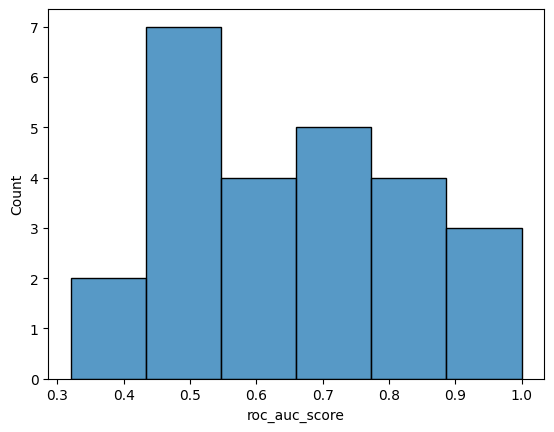

In [13]:
sns.histplot(per_epitope_roc_aucs_filtered, x='roc_auc_score')
plt.show()

In [14]:
stats.ttest_1samp(per_epitope_roc_aucs_filtered['roc_auc_score'], 0.5, alternative='greater')

TtestResult(statistic=4.0993001771688835, pvalue=0.00020492720991753134, df=24)

In [15]:
weighted_average = np.average(
    per_epitope_roc_aucs_filtered['roc_auc_score'],
    weights=(
        per_epitope_roc_aucs_filtered['number_of_complexes']
        / per_epitope_roc_aucs_filtered['number_of_complexes'].sum()
    ),
)

print('Weighted average ROC-AUC:', weighted_average)

Weighted average ROC-AUC: 0.5728410820160015
